# Phase 6: Budget Allocation and Business Recommendation

**Goal:** turn the Phase 5 results into a budget recommendation that a non-technical reader can act on, separating measured results from assumed costs.

The rules were committed in `reports/decisions.md`, under "Rules for Phase 6", before any Phase 6 quantity was calculated. They were written after the Phase 5 results were known.

- **Holdout values** come only from the saved Phase 5 tables, which must match the hashes recorded in the rules. The notebook never loads a holdout score or a holdout label.
- **New quantities**, the budget curve, band uplift and break-even curve, use the 160,031 pooled out-of-fold development rows. They are context and never choose the recommendation.
- **Costs** are assumed cost-to-margin ratios, `r = c / m`, of 1%, 3% and 5%. There is no currency.

**Net value per 100,000 customers, in purchaser-equivalents:** incremental purchasers per 100,000 minus `100,000 x K x r`. One purchaser-equivalent is the margin of one incremental purchaser. Any number with an assumed input is labelled **Assumed**.

`target` means a purchase in an undocumented period after communication. Observed checks are consistent with random assignment, but randomisation is not documented. Causal claims depend on that assumption.

## Setup

In [1]:
import hashlib
import math
import os
import re
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

sys.path.insert(0, str(ROOT / "notebooks"))
from targeting import overall_difference, score_ranks, select_by_rank, uplift_at_budgets, uplift_at_k_by_rank

TABLES = Path("outputs/tables")
FIGURES = Path("outputs/figures")
PROCESSED = Path("data/processed")
SPLITS_PATH = PROCESSED / "splits.parquet"
LABELS_PATH = PROCESSED / "uplift_train.parquet"
OOF_SCORES_PATH = PROCESSED / "scores_oof.parquet"
DECISIONS_PATH = Path("reports/decisions.md")
MEMO_PATH = Path("reports/decision_memo.md")

# Holdout guard: the saved Phase 5 tables, by the SHA-256 of their LF content, recorded in "Rules for Phase 6".
PHASE5_TABLES = {
    "holdout_strategy_results.csv": "12734dd300e96f46018706e062850433b940cb602a46124aa2b64441fc4b8135",
    "oof_strategy_results.csv": "c439298cb7acaccc27a3f3f9e8386f60db41b7cd607209deab6e8f2ef9958387",
    "primary_result.csv": "b2b2a9ecbdb6cc7dae68eb5e2b950652c3dbb3367ef846726f7d259eeb87ca87",
}
LOCK_COMMIT_SHA = "8c468b5"

SCENARIOS = (("Optimistic", 0.01), ("Moderate", 0.03), ("Conservative", 0.05))
LOCKED_BUDGETS = (5, 10, 20, 30)
CANDIDATE_BUDGETS = (0, 5, 10, 20, 30, 100)
CURVE_BUDGETS = tuple(range(5, 101, 5))
BANDS = ((0, 5), (5, 10), (10, 20), (20, 30), (30, 100))
BREAK_EVEN_STEP_PTS = 0.1
MATCH_TOLERANCE = 1e-12
PER = 100_000

EXPECTED_DEVELOPMENT = 160_031
EXPECTED_TREATED_DEVELOPMENT = 79_985
EXPECTED_CONTROL_DEVELOPMENT = 80_046

# Chart colours: categorical slots 1 and 2 of the reference palette, as in notebook 04, with neutral ink.
COLOURS = {"Response": "#2a78d6", "Uplift": "#eb6834", "Random": "#8a8983", "ink": "#3d3d3a", "muted": "#b9b8b1", "grid": "#e4e3de"}
plt.rcParams.update({
    "axes.edgecolor": COLOURS["grid"], "axes.labelcolor": COLOURS["ink"], "xtick.color": COLOURS["ink"],
    "ytick.color": COLOURS["ink"], "axes.grid": True, "grid.color": COLOURS["grid"], "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "lines.linewidth": 2,
})


def show(table, formats):
    """Display a copy of the table with the given columns formatted. jinja2 is not installed, so pandas styling is not used."""
    shown = table.copy()
    for column, pattern in formats.items():
        if column in shown:
            shown[column] = shown[column].map(lambda value: "" if pd.isna(value) else pattern.format(value))
    display(shown)

## 1. Helpers used only in this notebook

These follow the Phase 6 rules directly: the line-ending-safe hash, net value, the recommendation rule with its close call flag, and band uplift.

In [2]:
def lf_sha256_bytes(data):
    """SHA-256 after converting CRLF to LF, so a Windows checkout gives the recorded value."""
    return hashlib.sha256(data.replace(b"\r\n", b"\n")).hexdigest()


def lf_sha256(path):
    return lf_sha256_bytes(Path(path).read_bytes())


def net_per_100k(per_100k, budget_pct, r):
    """Incremental purchasers per 100,000 minus the cost of contacting K% of them, in purchaser-equivalents."""
    return per_100k - PER * budget_pct / 100 * r


def choose(candidates):
    """The Phase 6 recommendation rule on a table of candidates with budget_pct, net, net_ci_low and net_ci_high.

    The highest net value wins, an exact tie goes to the smaller budget, and contact no one (budget 0, net 0) is always a
    candidate, so it wins whenever no contacting candidate is positive. The close call flag is reporting only.
    """
    table = candidates.sort_values(["net", "budget_pct"], ascending=[False, True], kind="stable").reset_index(drop=True)
    if table["budget_pct"].duplicated().any() or 0 not in set(table["budget_pct"]):
        raise ValueError("Candidates must be distinct budgets and include contact no one")
    best, runner_up = table.iloc[0], table.iloc[1]
    if best["budget_pct"] == 0:
        close_call = bool(runner_up["net_ci_low"] <= 0 <= runner_up["net_ci_high"])
    else:
        close_call = bool(best["net_ci_low"] <= runner_up["net"] <= best["net_ci_high"])
    return {"best": best, "runner_up": runner_up, "close_call": close_call}


def band_uplift(ranks, treatment, target, low, high):
    """Treated rate minus control rate among rows ranked in the top high% but not the top low%, through select_by_rank."""
    inside = select_by_rank(ranks, high)
    if low > 0:
        inside &= ~select_by_rank(ranks, low)
    treated, control = inside & (treatment == 1), inside & (treatment == 0)
    if not treated.any() or not control.any():
        raise ValueError(f"The {low}-{high}% band holds only one arm")
    treated_rate, control_rate = target[treated].mean(), target[control].mean()
    return {"customers": int(inside.sum()), "treated": int(treated.sum()), "control": int(control.sum()),
            "treated_rate": treated_rate, "control_rate": control_rate, "uplift": treated_rate - control_rate}


def candidate_label(budget_pct):
    return {0: "Contact no one", 100: "Contact everyone"}.get(budget_pct, f"Top {budget_pct}% by estimated uplift")

## 2. Known-answer checks

Each helper runs on small constructed inputs first, and every result must match a value worked out by hand.

In [3]:
def rejected(call):
    try:
        call()
    except ValueError:
        return True
    return False


def candidates(rows):
    return pd.DataFrame(rows, columns=["budget_pct", "net", "net_ci_low", "net_ci_high"])


# Line endings do not change the hash.
assert lf_sha256_bytes(b"a,b\r\n1,2\r\n") == lf_sha256_bytes(b"a,b\n1,2\n") == hashlib.sha256(b"a,b\n1,2\n").hexdigest()

# Net value: 1,000 per 100,000 at a 20% budget and r = 3% leaves 1,000 - 600 = 400.
assert math.isclose(net_per_100k(1_000, 20, 0.03), 400)
assert math.isclose(net_per_100k(3_000, 100, 0.01), 2_000)
assert net_per_100k(500, 0, 0.05) == 500

# The highest net value wins. The runner-up at 450 lies inside the best interval of 400 to 600, so it is a close call.
pick = choose(candidates([(0, 0, np.nan, np.nan), (5, 300, 200, 400), (10, 500, 400, 600), (20, 450, 300, 600)]))
assert pick["best"]["budget_pct"] == 10 and pick["runner_up"]["budget_pct"] == 20 and pick["close_call"]
pick = choose(candidates([(0, 0, np.nan, np.nan), (5, 300, 200, 400), (10, 500, 460, 600), (20, 450, 300, 600)]))
assert pick["best"]["budget_pct"] == 10 and not pick["close_call"]
# Ends of the interval count as inside.
assert choose(candidates([(0, 0, np.nan, np.nan), (10, 500, 450, 600), (20, 450, 300, 600)]))["close_call"]
# An exact tie goes to the smaller budget.
assert choose(candidates([(0, 0, np.nan, np.nan), (10, 200, 100, 300), (5, 200, 100, 300)]))["best"]["budget_pct"] == 5
# No positive candidate: contact no one. A close call when the runner-up's interval includes zero.
pick = choose(candidates([(0, 0, np.nan, np.nan), (5, -10, -50, 30), (10, -20, -60, -1)]))
assert pick["best"]["budget_pct"] == 0 and pick["runner_up"]["budget_pct"] == 5 and pick["close_call"]
assert not choose(candidates([(0, 0, np.nan, np.nan), (5, -10, -50, -2)]))["close_call"]
# A candidate at exactly zero ties with contact no one, which is the smaller budget.
assert choose(candidates([(0, 0, np.nan, np.nan), (5, 0, -40, 40)]))["best"]["budget_pct"] == 0
assert rejected(lambda: choose(candidates([(5, 10, 0, 20), (10, 5, 0, 10)])))

# Band uplift. Top 4 of 10: treated rows 0 and 2 both buy, control rows 1 and 3 give 0.5, so 0.5, as in notebook 04.
RANKS = np.arange(10)
ARM = np.array([1, 0, 1, 0, 1, 0, 1, 0, 1, 0])
BUY = np.array([1, 0, 1, 1, 0, 0, 1, 0, 0, 0])
assert band_uplift(RANKS, ARM, BUY, 0, 40)["uplift"] == uplift_at_k_by_rank(RANKS, ARM, BUY, 40) == 0.5
# Rows 4 to 9: treated rows 4, 6 and 8 buy 1 of 3, control rows 5, 7 and 9 buy none.
band = band_uplift(RANKS, ARM, BUY, 40, 100)
assert band["customers"] == 6 and band["treated"] == 3 and band["control"] == 3 and math.isclose(band["uplift"], 1 / 3)
shuffled_order = np.array([9, 3, 0, 7, 1, 8, 2, 6, 4, 5])
assert math.isclose(band_uplift(RANKS[shuffled_order], ARM[shuffled_order], BUY[shuffled_order], 40, 100)["uplift"], 1 / 3)
assert rejected(lambda: band_uplift(RANKS, ARM, BUY, 0, 10))  # one treated row, no control row

# Bands between locked points cover every row exactly once.
band_rng = np.random.default_rng(0)
ranks_check = band_rng.permutation(1_003)
covered = np.zeros(1_003, dtype=int)
for low, high in BANDS:
    inside = select_by_rank(ranks_check, high) & ~(select_by_rank(ranks_check, low) if low else np.zeros(1_003, bool))
    covered += inside
assert (covered == 1).all()
print("All known-answer checks passed.")

All known-answer checks passed.


## 3. Holdout guard

The saved Phase 5 tables must match the hashes recorded in "Rules for Phase 6", and the primary result must carry the Phase 5 lock commit. The hashes in this notebook must also appear in that log, so the two cannot drift apart. Nothing else is read from the holdout.

In [4]:
decisions_text = DECISIONS_PATH.read_text(encoding="utf-8")
assert "## Rules for Phase 6" in decisions_text, "The Phase 6 rules are missing from the decisions log"
for name, recorded in PHASE5_TABLES.items():
    assert f"| `{name}` | `{recorded}` |" in decisions_text, f"The hash for {name} differs from the decisions log"
    actual = lf_sha256(TABLES / name)
    assert actual == recorded, f"{name} differs from the Phase 6 record: {actual}"
    print(f"{name}: hash matches")

primary = pd.read_csv(TABLES / "primary_result.csv", dtype={"lock_commit": str})
assert len(primary) == 1 and primary.loc[0, "lock_commit"] == LOCK_COMMIT_SHA, "The primary result does not carry the lock commit"
print(f"Lock commit {LOCK_COMMIT_SHA} recorded in primary_result.csv")

holdout_strategy_results.csv: hash matches
oof_strategy_results.csv: hash matches
primary_result.csv: hash matches
Lock commit 8c468b5 recorded in primary_result.csv


## 4. Phase 5 results used here

Incremental purchasers per 100,000, with intervals, for every strategy and budget, on both evaluation sets. These are **Measured** in Phase 5. The values quoted in the decisions log are checked here, and the primary difference must equal the difference of the two strategy rows.

In [5]:
STRATEGY_NAMES = {"Random (expected value of random targeting)": "Random", "Response": "Response", "Uplift": "Uplift",
                  "Contact everyone": "Contact everyone"}
strategy_tables = []
for set_name, file_name in (("holdout", "holdout_strategy_results.csv"), ("out-of-fold", "oof_strategy_results.csv")):
    table = pd.read_csv(TABLES / file_name)
    assert len(table) == 13 and (table["set"] == set_name).all()
    assert set(table["strategy"]) == set(STRATEGY_NAMES)
    for name in ("Random (expected value of random targeting)", "Response", "Uplift"):
        assert tuple(table.loc[table["strategy"] == name, "budget_pct"]) == LOCKED_BUDGETS
    assert tuple(table.loc[table["strategy"] == "Contact everyone", "budget_pct"]) == (100,)
    strategy_tables.append(table.assign(strategy=table["strategy"].map(STRATEGY_NAMES)))
phase5 = pd.concat(strategy_tables, ignore_index=True)


def phase5_value(set_name, strategy, budget, column="per_100k"):
    row = phase5[(phase5["set"] == set_name) & (phase5["strategy"] == strategy) & (phase5["budget_pct"] == budget)]
    assert len(row) == 1
    return row[column].iloc[0]


# The primary result is the uplift row minus the response row at 20% on the holdout.
difference = phase5_value("holdout", "Uplift", 20, "uplift_pts") - phase5_value("holdout", "Response", 20, "uplift_pts")
assert abs(difference - primary.loc[0, "difference_pts"]) < MATCH_TOLERANCE
# Values quoted in the decisions log and the memo headline.
assert (round(primary.loc[0, "difference_pts"], 2), round(primary.loc[0, "ci_low_pts"], 2), round(primary.loc[0, "ci_high_pts"], 2)) == (5.05, 2.55, 7.34)
assert (round(primary.loc[0, "per_100k"]), round(primary.loc[0, "per_100k_ci_low"]), round(primary.loc[0, "per_100k_ci_high"])) == (1010, 510, 1467)
assert round(phase5_value("holdout", "Contact everyone", 100, "uplift_pts"), 2) == 3.32
show(phase5[["set", "strategy", "budget_pct", "uplift_pts", "per_100k", "per_100k_ci_low", "per_100k_ci_high", "label"]],
     {"uplift_pts": "{:+.2f}", "per_100k": "{:+,.0f}", "per_100k_ci_low": "{:+,.0f}", "per_100k_ci_high": "{:+,.0f}"})

,set,strategy,budget_pct,uplift_pts,per_100k,per_100k_ci_low,per_100k_ci_high,label
0,holdout,Random,5,+3.32,+166,+116,+214,Exploratory
1,holdout,Response,5,+0.54,+27,-32,+94,Exploratory
2,holdout,Uplift,5,+16.24,+812,+594,"+1,020",Exploratory
3,holdout,Random,10,+3.32,+332,+232,+427,Secondary
4,holdout,Response,10,+0.61,+61,-63,+179,Secondary
5,holdout,Uplift,10,+11.02,"+1,102",+781,"+1,398",Secondary
6,holdout,Random,20,+3.32,+665,+464,+855,Secondary
7,holdout,Response,20,+1.21,+242,+20,+481,Secondary
8,holdout,Uplift,20,+6.26,"+1,252",+798,"+1,669",Secondary
9,holdout,Random,30,+3.32,+997,+696,"+1,282",Secondary


## 5. Net value under each scenario

`net = per_100k - 100,000 x K x r`. For a fixed `r` the cost term is the same in every resample, so the Phase 5 interval shifted by it is exact, and no new bootstrap is needed. Every value is **Assumed**, because `r` is assumed.

In [6]:
net_rows = []
for scenario, r in SCENARIOS:
    for row in phase5.itertuples(index=False):
        cost = PER * row.budget_pct / 100 * r
        net_rows.append({
            "set": row.set, "scenario": scenario, "r": r, "strategy": row.strategy, "budget_pct": row.budget_pct,
            "per_100k": row.per_100k, "per_100k_ci_low": row.per_100k_ci_low, "per_100k_ci_high": row.per_100k_ci_high,
            "net": net_per_100k(row.per_100k, row.budget_pct, r),
            "net_ci_low": row.per_100k_ci_low - cost, "net_ci_high": row.per_100k_ci_high - cost,
            "label": f"Assumed (Measured {row.set} incremental purchasers, c/m = {r:.0%})",
        })
net_values = pd.DataFrame(net_rows)
net_values.to_csv(TABLES / "net_value_scenarios.csv", index=False)
show(net_values[net_values["strategy"].isin(["Uplift", "Contact everyone"])].drop(columns=["label", "per_100k_ci_low", "per_100k_ci_high"]),
     {"r": "{:.0%}", "per_100k": "{:+,.0f}", "net": "{:+,.0f}", "net_ci_low": "{:+,.0f}", "net_ci_high": "{:+,.0f}"})

,set,scenario,r,strategy,budget_pct,per_100k,net,net_ci_low,net_ci_high
2,holdout,Optimistic,1%,Uplift,5,+812,+762,+544,+970
5,holdout,Optimistic,1%,Uplift,10,"+1,102","+1,002",+681,"+1,298"
8,holdout,Optimistic,1%,Uplift,20,"+1,252","+1,052",+598,"+1,469"
11,holdout,Optimistic,1%,Uplift,30,"+1,424","+1,124",+583,"+1,649"
12,holdout,Optimistic,1%,Contact everyone,100,"+3,324","+2,324","+1,319","+3,274"
15,out-of-fold,Optimistic,1%,Uplift,5,+579,+529,+427,+641
18,out-of-fold,Optimistic,1%,Uplift,10,+928,+828,+678,+982
21,out-of-fold,Optimistic,1%,Uplift,20,"+1,424","+1,224","+1,006","+1,433"
24,out-of-fold,Optimistic,1%,Uplift,30,"+1,762","+1,462","+1,180","+1,719"
25,out-of-fold,Optimistic,1%,Contact everyone,100,"+3,323","+2,323","+1,857","+2,782"


## 6. Recommendation

For each scenario the candidates are the uplift strategy at 5%, 10%, 20% and 30%, contact everyone and contact no one. The choice is the highest **out-of-fold** net value. The holdout net value at that point is reported beside it, with the candidate the holdout would rank highest under the same rule. The out-of-fold choice stands either way.

In [7]:
def candidate_table(set_name, scenario):
    rows = net_values[(net_values["set"] == set_name) & (net_values["scenario"] == scenario)
                      & (((net_values["strategy"] == "Uplift") & net_values["budget_pct"].isin(LOCKED_BUDGETS))
                         | (net_values["strategy"] == "Contact everyone"))]
    table = rows[["budget_pct", "net", "net_ci_low", "net_ci_high"]]
    table = pd.concat([pd.DataFrame([{"budget_pct": 0, "net": 0.0, "net_ci_low": np.nan, "net_ci_high": np.nan}]), table], ignore_index=True)
    assert tuple(sorted(table["budget_pct"])) == CANDIDATE_BUDGETS
    return table


recommendation_rows = []
for scenario, r in SCENARIOS:
    oof_pick = choose(candidate_table("out-of-fold", scenario))
    holdout_candidates = candidate_table("holdout", scenario)
    holdout_pick = choose(holdout_candidates)
    best, runner_up = oof_pick["best"], oof_pick["runner_up"]
    at_choice = holdout_candidates[holdout_candidates["budget_pct"] == best["budget_pct"]].iloc[0]
    recommendation_rows.append({
        "scenario": scenario, "r": r, "choice_budget_pct": int(best["budget_pct"]), "choice": candidate_label(int(best["budget_pct"])),
        "oof_net": best["net"], "oof_net_ci_low": best["net_ci_low"], "oof_net_ci_high": best["net_ci_high"],
        "runner_up_budget_pct": int(runner_up["budget_pct"]), "runner_up_oof_net": runner_up["net"], "close_call": oof_pick["close_call"],
        "holdout_net": at_choice["net"], "holdout_net_ci_low": at_choice["net_ci_low"], "holdout_net_ci_high": at_choice["net_ci_high"],
        "holdout_best_budget_pct": int(holdout_pick["best"]["budget_pct"]), "holdout_best_net": holdout_pick["best"]["net"],
        "holdout_disagrees": int(holdout_pick["best"]["budget_pct"]) != int(best["budget_pct"]),
        "label": f"Assumed (Measured out-of-fold and holdout incremental purchasers, c/m = {r:.0%})",
    })
recommendation = pd.DataFrame(recommendation_rows)
recommendation.to_csv(TABLES / "recommendation.csv", index=False)
money = "{:+,.0f}"
show(recommendation.drop(columns=["label"]),
     {"r": "{:.0%}", "oof_net": money, "oof_net_ci_low": money, "oof_net_ci_high": money, "runner_up_oof_net": money,
      "holdout_net": money, "holdout_net_ci_low": money, "holdout_net_ci_high": money, "holdout_best_net": money})

,scenario,r,choice_budget_pct,choice,oof_net,oof_net_ci_low,oof_net_ci_high,runner_up_budget_pct,runner_up_oof_net,close_call,holdout_net,holdout_net_ci_low,holdout_net_ci_high,holdout_best_budget_pct,holdout_best_net,holdout_disagrees
0,Optimistic,1%,100,Contact everyone,"+2,323","+1,857","+2,782",30,"+1,462",False,"+2,324","+1,319","+3,274",100,"+2,324",False
1,Moderate,3%,30,Top 30% by estimated uplift,+862,+580,"+1,119",20,+824,True,+524,-17,"+1,049",10,+802,True
2,Conservative,5%,10,Top 10% by estimated uplift,+428,+278,+582,20,+424,True,+602,+281,+898,10,+602,False


## 7. Load the development customers

The out-of-fold scores with their development labels, filtered to `split = 'development'`. This is the only label query in the notebook, and it cannot return a holdout row.

In [8]:
con = duckdb.connect()
development = con.execute(
    f"""
    SELECT o.client_id, o.m1_score, o.tau, l.treatment_flg, l.target, s.split
    FROM '{OOF_SCORES_PATH}' AS o
    JOIN '{SPLITS_PATH}' AS s USING (client_id)
    JOIN '{LABELS_PATH}' AS l USING (client_id)
    WHERE s.split = 'development'
    ORDER BY o.client_id
    """
).fetchdf()
oof_ids = con.execute(f"SELECT client_id FROM '{OOF_SCORES_PATH}' ORDER BY client_id").fetchdf()["client_id"]
con.close()

assert len(development) == EXPECTED_DEVELOPMENT and (development["split"] == "development").all()
assert development["client_id"].is_unique and development["client_id"].tolist() == oof_ids.tolist()
assert (development["treatment_flg"] == 1).sum() == EXPECTED_TREATED_DEVELOPMENT
assert (development["treatment_flg"] == 0).sum() == EXPECTED_CONTROL_DEVELOPMENT
assert development["target"].isin([0, 1]).all()

ids = development["client_id"].to_numpy(dtype=object)
treatment = development["treatment_flg"].to_numpy(dtype=np.int64)
target = development["target"].to_numpy(dtype=np.int64)
RANKS_BY_STRATEGY = {"Uplift": score_ranks(ids, development["tau"].to_numpy()),
                     "Response": score_ranks(ids, development["m1_score"].to_numpy())}
print(f"{len(development):,} development customers: {treatment.sum():,} treated and {(1 - treatment).sum():,} control")

160,031 development customers: 79,985 treated and 80,046 control


## 8. Budget curve (context)

Uplift@K and net value under each scenario from 5% to 100% in 5% steps, on the pooled out-of-fold rows. The values at the locked points must match the Phase 5 table within 1e-12. Random is its straight-line expected value. No intervals, and this never chooses the recommendation.

In [9]:
oof_overall = overall_difference(treatment, target)
assert abs(oof_overall * 100 - phase5_value("out-of-fold", "Contact everyone", 100, "uplift_pts")) < MATCH_TOLERANCE
assert abs(oof_overall * 100 - phase5_value("out-of-fold", "Random", 20, "uplift_pts")) < MATCH_TOLERANCE

curve_rows = []
for strategy, ranks in RANKS_BY_STRATEGY.items():
    uplifts = uplift_at_budgets(ranks, treatment, target, list(CURVE_BUDGETS))
    for budget, uplift in uplifts.items():
        expected = (phase5_value("out-of-fold", strategy, budget, "uplift_pts") if budget in LOCKED_BUDGETS
                    else phase5_value("out-of-fold", "Contact everyone", 100, "uplift_pts") if budget == 100 else None)
        if expected is not None:
            assert abs(uplift * 100 - expected) < MATCH_TOLERANCE, f"{strategy} at {budget}% differs from Phase 5"
        curve_rows.append({"strategy": strategy, "budget_pct": budget, "uplift_pts": uplift * 100, "per_100k": PER * budget / 100 * uplift})
for budget in CURVE_BUDGETS:
    curve_rows.append({"strategy": "Random", "budget_pct": budget, "uplift_pts": oof_overall * 100, "per_100k": PER * budget / 100 * oof_overall})
budget_curve = pd.DataFrame(curve_rows)
for scenario, r in SCENARIOS:
    budget_curve[f"net_{scenario.lower()}"] = net_per_100k(budget_curve["per_100k"], budget_curve["budget_pct"], r)
budget_curve["label"] = "Context (Measured out-of-fold; net values Assumed)"
budget_curve.to_csv(TABLES / "oof_budget_curve.csv", index=False)
print("Locked points match the Phase 5 out-of-fold table.")
show(budget_curve[budget_curve["strategy"] != "Random"].pivot(index="budget_pct", columns="strategy", values="per_100k").reset_index(),
     {"Response": "{:+,.0f}", "Uplift": "{:+,.0f}"})

Locked points match the Phase 5 out-of-fold table.


strategy,budget_pct,Response,Uplift
0,5,+16,+579
1,10,+133,+928
2,15,+212,"+1,276"
3,20,+290,"+1,424"
4,25,+426,"+1,699"
5,30,+551,"+1,762"
6,35,+766,"+1,932"
7,40,+917,"+2,189"
8,45,"+1,053","+2,264"
9,50,"+1,277","+2,464"


## 9. Band uplift (context)

The treated rate minus the control rate among the customers in each band between locked points, for each strategy. A band is the top K2% minus the top K1% on the same ranks. Each band is compared with each scenario's `r`: contacting a band adds net value under that scenario only if its uplift is above `r`.

In [10]:
band_rows = []
for strategy, ranks in RANKS_BY_STRATEGY.items():
    for low, high in BANDS:
        values = band_uplift(ranks, treatment, target, low, high)
        row = {"strategy": strategy, "band": f"{low}-{high}%", "low_pct": low, "high_pct": high, **values,
               "uplift_pts": values["uplift"] * 100}
        for scenario, r in SCENARIOS:
            row[f"above_r_{scenario.lower()}"] = values["uplift"] > r
        band_rows.append(row)
bands = pd.DataFrame(band_rows).drop(columns=["uplift"])
assert (bands.groupby("strategy")["customers"].sum() == EXPECTED_DEVELOPMENT).all()
bands["label"] = "Context (Measured out-of-fold; comparison with r Assumed)"
bands.to_csv(TABLES / "oof_band_uplift.csv", index=False)
show(bands.drop(columns=["label", "low_pct", "high_pct"]), {"treated_rate": "{:.2%}", "control_rate": "{:.2%}", "uplift_pts": "{:+.2f}"})

,strategy,band,customers,treated,control,treated_rate,control_rate,uplift_pts,above_r_optimistic,above_r_moderate,above_r_conservative
0,Uplift,0-5%,8002,4000,4002,54.85%,43.28%,+11.57,True,True,True
1,Uplift,5-10%,8001,3984,4017,55.95%,48.94%,+7.01,True,True,True
2,Uplift,10-20%,16003,7903,8100,55.73%,50.74%,+4.98,True,True,False
3,Uplift,20-30%,16003,7946,8057,59.24%,55.86%,+3.37,True,True,False
4,Uplift,30-100%,112022,56152,55870,66.56%,64.40%,+2.16,True,False,False
5,Response,0-5%,8002,4028,3974,97.52%,97.21%,+0.31,False,False,False
6,Response,5-10%,8001,4003,3998,95.43%,93.10%,+2.33,True,False,False
7,Response,10-20%,16003,8079,7924,89.94%,88.33%,+1.61,True,False,False
8,Response,20-30%,16003,7925,8078,83.29%,80.91%,+2.38,True,False,False
9,Response,30-100%,112022,55950,56072,52.36%,48.46%,+3.91,True,True,False


## 10. Break-even curve

`r` from 0 to the highest out-of-fold Uplift@K at any locked point, across all strategies, rounded up to the next whole point, in steps of 0.1 point. At each `r`, every candidate's out-of-fold net value and the best candidate under the recommendation rule. The switching points between best candidates are also given exactly, from where the two straight lines cross.

In [11]:
oof_locked = phase5[phase5["set"] == "out-of-fold"]
max_uplift_pts = oof_locked["uplift_pts"].max()
R_MAX_PTS = math.ceil(max_uplift_pts)
print(f"Highest out-of-fold Uplift@K at a locked point: {max_uplift_pts:.2f} points, so r runs from 0 to {R_MAX_PTS} points")

candidate_per_100k = {0: 0.0, 100: phase5_value("out-of-fold", "Contact everyone", 100)}
candidate_per_100k.update({budget: phase5_value("out-of-fold", "Uplift", budget) for budget in LOCKED_BUDGETS})
r_grid_pts = np.round(np.arange(0, round(R_MAX_PTS / BREAK_EVEN_STEP_PTS) + 1) * BREAK_EVEN_STEP_PTS, 1)

break_even_rows = []
for r_pts in r_grid_pts:
    table = pd.DataFrame([{"budget_pct": budget, "net": net_per_100k(value, budget, r_pts / 100), "net_ci_low": np.nan, "net_ci_high": np.nan}
                          for budget, value in candidate_per_100k.items()])
    best = choose(table)["best"]
    row = {"r_pts": r_pts}
    row.update({f"net_{budget}": net for budget, net in zip(table["budget_pct"], table["net"])})
    row.update({"best_budget_pct": int(best["budget_pct"]), "best": candidate_label(int(best["budget_pct"])), "best_net": best["net"]})
    break_even_rows.append(row)
break_even = pd.DataFrame(break_even_rows)
break_even["label"] = "Assumed (Measured out-of-fold incremental purchasers, c/m on the grid)"
break_even.to_csv(TABLES / "break_even_curve.csv", index=False)

# Exact switching points: where the line of one best candidate crosses the next.
segments = []
for budget, rows in break_even.groupby((break_even["best_budget_pct"] != break_even["best_budget_pct"].shift()).cumsum()):
    segments.append((int(rows["best_budget_pct"].iloc[0]), rows["r_pts"].iloc[0], rows["r_pts"].iloc[-1]))
switches = []
for (before, *_), (after, *_) in zip(segments, segments[1:]):
    crossing = (candidate_per_100k[before] - candidate_per_100k[after]) / (PER * (before - after) / 100) * 100
    switches.append({"from": candidate_label(before), "to": candidate_label(after), "switch_at_r_pts": crossing})
switch_table = pd.DataFrame(switches)
for _, row in switch_table.iterrows():
    print(f"{row['from']} -> {row['to']} at c/m = {row['switch_at_r_pts']:.2f}%")
show(pd.DataFrame(segments, columns=["best_budget_pct", "from_r_pts", "to_r_pts"]), {"from_r_pts": "{:.1f}", "to_r_pts": "{:.1f}"})

Highest out-of-fold Uplift@K at a locked point: 11.57 points, so r runs from 0 to 12 points
Contact everyone -> Top 30% by estimated uplift at c/m = 2.23%
Top 30% by estimated uplift -> Top 20% by estimated uplift at c/m = 3.38%
Top 20% by estimated uplift -> Top 10% by estimated uplift at c/m = 4.96%
Top 10% by estimated uplift -> Top 5% by estimated uplift at c/m = 6.99%
Top 5% by estimated uplift -> Contact no one at c/m = 11.57%


,best_budget_pct,from_r_pts,to_r_pts
0,100,0.0,2.2
1,30,2.3,3.3
2,20,3.4,4.9
3,10,5.0,6.9
4,5,7.0,11.5
5,0,11.6,12.0


## 11. Figures

**Net value by budget:** one panel per scenario. Lines are the out-of-fold context curve, markers are the holdout values at the locked points with their 95% intervals, and the dotted line marks the out-of-fold choice.

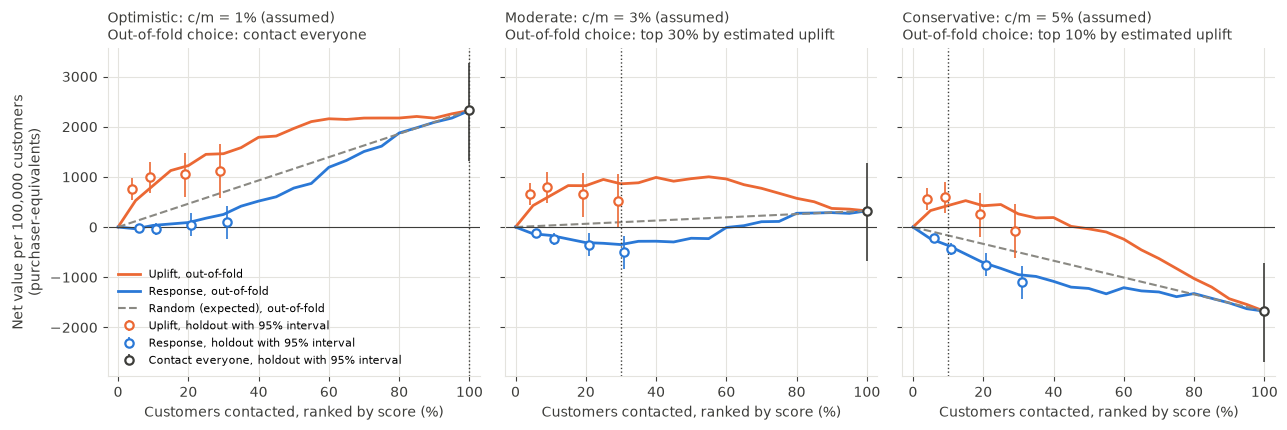

In [12]:
figure, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
budgets_axis = np.array((0,) + CURVE_BUDGETS)
for axis, (scenario, r) in zip(axes, SCENARIOS):
    column = f"net_{scenario.lower()}"
    for strategy in ("Uplift", "Response", "Random"):
        values = budget_curve[budget_curve["strategy"] == strategy].sort_values("budget_pct")[column].to_numpy()
        axis.plot(budgets_axis, np.concatenate(([0.0], values)), color=COLOURS[strategy],
                  linestyle="--" if strategy == "Random" else "-", linewidth=1.5 if strategy == "Random" else 2,
                  label=f"{'Random (expected)' if strategy == 'Random' else strategy}, out-of-fold")
    holdout = net_values[(net_values["set"] == "holdout") & (net_values["scenario"] == scenario)]
    for strategy, offset, marker_colour in (("Uplift", -0.9, COLOURS["Uplift"]), ("Response", 0.9, COLOURS["Response"]),
                                            ("Contact everyone", 0.0, COLOURS["ink"])):
        rows = holdout[holdout["strategy"] == strategy]
        axis.errorbar(rows["budget_pct"] + offset, rows["net"], yerr=[rows["net"] - rows["net_ci_low"], rows["net_ci_high"] - rows["net"]],
                      fmt="o", markersize=6, markerfacecolor="white", markeredgewidth=1.6, color=marker_colour, elinewidth=1.2,
                      capsize=0, label=f"{strategy}, holdout with 95% interval" if axis is axes[0] else None)
    choice = recommendation.loc[recommendation["scenario"] == scenario].iloc[0]
    axis.axvline(choice["choice_budget_pct"], color=COLOURS["ink"], linestyle=":", linewidth=1)
    axis.axhline(0, color=COLOURS["ink"], linewidth=0.8)
    axis.set_title(f"{scenario}: c/m = {r:.0%} (assumed)\nOut-of-fold choice: {choice['choice'].lower()}", color=COLOURS["ink"], loc="left", fontsize=10)
    axis.set_xlabel("Customers contacted, ranked by score (%)")
    axis.set_xlim(-3, 103)
axes[0].set_ylabel("Net value per 100,000 customers\n(purchaser-equivalents)")
axes[0].legend(frameon=False, loc="lower left", fontsize=8)
figure.tight_layout()
figure.savefig(FIGURES / "net_value_by_budget.png", dpi=150, bbox_inches="tight")
plt.show()

**Break-even curve:** each grey line is one candidate's out-of-fold net value as the cost-to-margin ratio rises. The orange line is the best candidate at each ratio, so a reader can place their own ratio on the horizontal axis.

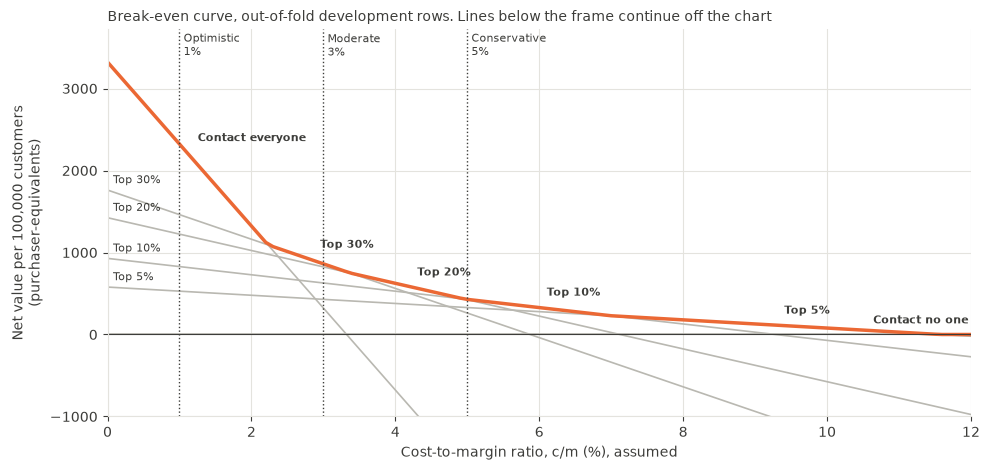

In [13]:
figure, axis = plt.subplots(figsize=(10, 4.8))
x = break_even["r_pts"].to_numpy()
for budget in CANDIDATE_BUDGETS:
    axis.plot(x, break_even[f"net_{budget}"], color=COLOURS["muted"], linewidth=1.2)
    if budget not in (0, 100):  # contact everyone and contact no one are named on the orange line
        start = break_even[f"net_{budget}"].iloc[0]
        axis.annotate(candidate_label(budget).replace(" by estimated uplift", ""), (0, start), xytext=(4, 3), textcoords="offset points",
                      ha="left", va="bottom", fontsize=8, color=COLOURS["ink"])
axis.plot(x, break_even["best_net"], color=COLOURS["Uplift"], linewidth=2.5, label="Best candidate")
for (budget, start, end) in segments:
    middle = (start + end) / 2
    y = break_even.loc[(break_even["r_pts"] - middle).abs().idxmin(), "best_net"]
    at_edge = middle > R_MAX_PTS - 1
    axis.annotate(candidate_label(budget).replace(" by estimated uplift", ""), (R_MAX_PTS if at_edge else middle, y),
                  xytext=(-2 if at_edge else 8, 8), textcoords="offset points", ha="right" if at_edge else "left",
                  fontsize=8, color=COLOURS["ink"], fontweight="bold")
for scenario, r in SCENARIOS:
    axis.axvline(r * 100, color=COLOURS["ink"], linestyle=":", linewidth=1)
    axis.annotate(f"{scenario}\n{r:.0%}", (r * 100, 1.0), xycoords=("data", "axes fraction"), xytext=(3, -2), textcoords="offset points",
                  va="top", fontsize=8, color=COLOURS["ink"])
axis.axhline(0, color=COLOURS["ink"], linewidth=0.8)
axis.set_xlim(0, R_MAX_PTS)
axis.set_ylim(-1_000, candidate_per_100k[100] * 1.12)
axis.set_xlabel("Cost-to-margin ratio, c/m (%), assumed")
axis.set_ylabel("Net value per 100,000 customers\n(purchaser-equivalents)")
axis.set_title("Break-even curve, out-of-fold development rows. Lines below the frame continue off the chart", color=COLOURS["ink"], loc="left", fontsize=10)
figure.tight_layout()
figure.savefig(FIGURES / "break_even_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Decision memo checks

`reports/decision_memo.md` must follow the memo rules: at most 450 words outside the title and tables, at most two tables and one figure, the five sections in order, the headline and assignment wording verbatim, no method terms, and every recommendation number as calculated above.

In [14]:
memo = MEMO_PATH.read_text(encoding="utf-8")
lines = memo.splitlines()
assert lines[0].startswith("# ")
body_lines = [line for line in lines[1:] if not line.lstrip().startswith("|")]
words = [token for token in " ".join(body_lines).split() if re.search(r"[A-Za-z0-9]", token)]
tables = sum(1 for line in lines if re.fullmatch(r"\|(\s*-+:?\s*\|)+\s*", line.replace(":", "")))
figures = memo.count(".png")
print(f"Memo: {len(words)} words outside the title and tables, {tables} tables, {figures} figure link")
assert len(words) <= 450 and tables <= 2 and figures <= 1

SECTIONS = ["## 1. Recommendation", "## 2. Evidence", "## 3. Measured results vs assumptions", "## 4. Limitations", "## 5. Next step"]
positions = [memo.find(section) for section in SECTIONS]
assert all(position >= 0 for position in positions) and positions == sorted(positions), "The memo sections are missing or out of order"

HEADLINE = ("At a 20% budget, targeting by estimated uplift produced about 1,010 more extra purchasers per 100k customers than "
            "targeting by purchase likelihood (95% range +510 to +1,467). **Measured (holdout).**")
ASSIGNMENT = "Observed checks are consistent with random assignment, but randomisation is not documented. Causal claims depend on that assumption."
assert HEADLINE in memo and ASSIGNMENT in memo
for term in ("Qini", "AUUC", "T-Learner", "bootstrap", "out-of-fold", "XGBoost", "tau"):
    assert term.lower() not in memo.lower(), f"Method term in the memo: {term}"


def with_range(value, low, high):
    return f"{value:+,.0f} ({low:+,.0f} to {high:+,.0f})"


for row in recommendation.itertuples(index=False):
    who = "Everyone" if row.choice_budget_pct == 100 else f"Top {row.choice_budget_pct}% by estimated uplift"
    expected = (f"| {row.r:.0%} | {who} | {with_range(row.oof_net, row.oof_net_ci_low, row.oof_net_ci_high)} | "
                f"{with_range(row.holdout_net, row.holdout_net_ci_low, row.holdout_net_ci_high)} |")
    assert expected in memo, f"Memo row differs from the calculation: {expected}"
    assert ("Close call" in memo.split(expected)[1].split("\n")[0]) == row.close_call
    assert ("favour" in memo.split(expected)[1].split("\n")[0]) == row.holdout_disagrees
for _, row in switch_table.iterrows():
    assert f"{row['switch_at_r_pts']:.1f}%" in memo, f"Switching point {row['switch_at_r_pts']:.2f}% is not in the memo"
print("The memo matches the rules and the calculated values.")

Memo: 348 words outside the title and tables, 2 tables, 1 figure link
The memo matches the rules and the calculated values.


## Phase 6 conclusion

The recommendation table above is the result. Every net value is **Assumed**, built from **Measured** incremental purchasers and an assumed cost-to-margin ratio. The out-of-fold choice stands where the holdout ranks another point higher, and the memo says so. Results are recorded in `reports/decisions.md` under "Phase 6 results", and the memo is `reports/decision_memo.md`.